# ROI_processing

In [1]:
import spatialdata_io
import spatialdata as sd
import troutpy
import scanpy as sc
from spatialdata import SpatialData
import matplotlib.pyplot as plt
from spatialdata.transformations import get_transformation
import matplotlib.patches as patches
import os
import numpy as np
import sys
import seaborn as sns
import hotspot

/home/sergio/.local/lib/python3.10/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(
/home/sergio/.local/lib/python3.10/site-packages/numba/core/decorators.py:246: RuntimeWarning: nopython is set for njit and is ignored
  warnings.warn('nopython is set for njit and is ignored', RuntimeWarning)
/home/sergio/.local/lib/python3.10/site-packages/anndata/utils.py:429: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_text instead.
  warnings.warn(msg, FutureWarning)
/home/sergio/.local/lib/python3.10/site-packages/anndata/utils.py:429: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_text instead.
  warnings.warn(msg, FutureWarning)


In [2]:
# Technology 1: Xenium
sdata = sd.read_zarr("/media/sergio/Meninges/troutpy/rois/xenium_msbrain_5k/data_processed.zarr")
results = sdata["xrna_metadata"].var

In [3]:
sc.pp.highly_variable_genes(sdata['table'], n_top_genes=500)

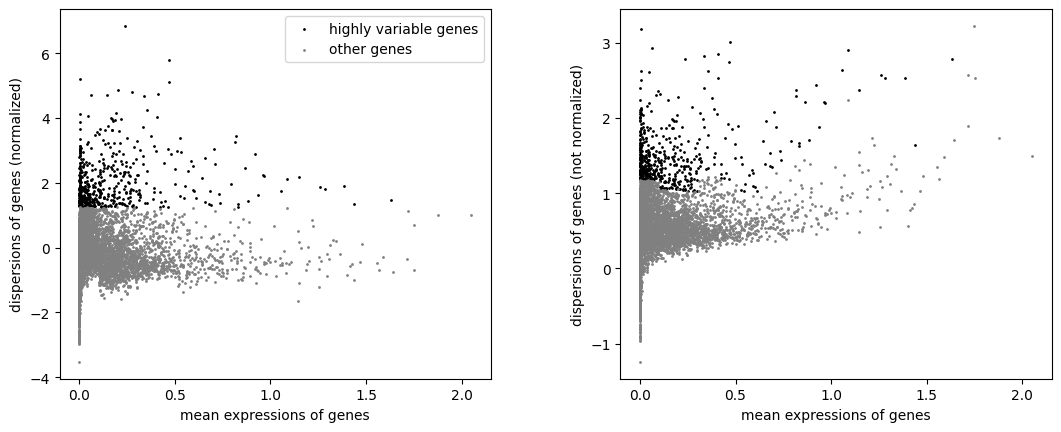

In [4]:
sc.pl.highly_variable_genes(sdata['table'])

In [5]:
sdata['table']=sdata['table'][:,sdata['table'].var['highly_variable']]
sc.tl.pca(sdata['table'])
sc.pp.neighbors(sdata['table'])

2025-07-08 10:28:07.227500: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2025-07-08 10:28:07.353285: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1751963287.408658 3059375 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1751963287.424565 3059375 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1751963287.532526 3059375 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking 

In [6]:
sc.tl.umap(sdata['table'])

In [7]:
sc.tl.leiden(sdata['table'],key_added='leiden_500')

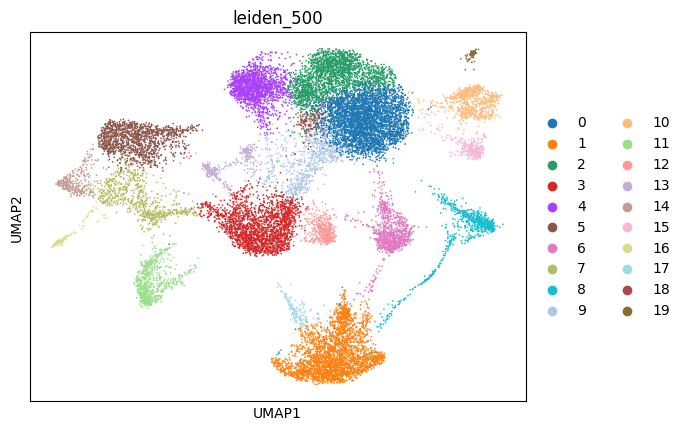

In [40]:
sc.pl.umap(sdata['table'],color=['leiden_500'])

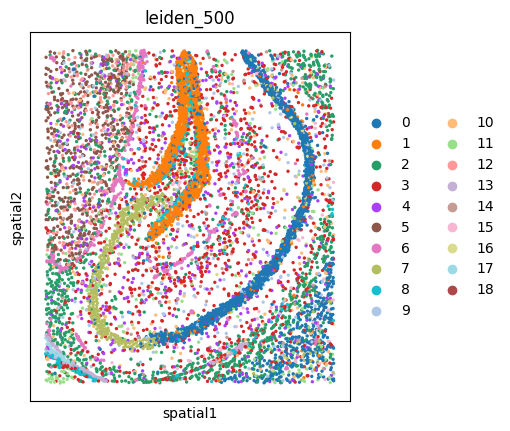

In [9]:
sc.pl.spatial(sdata['table'],color=['leiden_500'],spot_size=20)

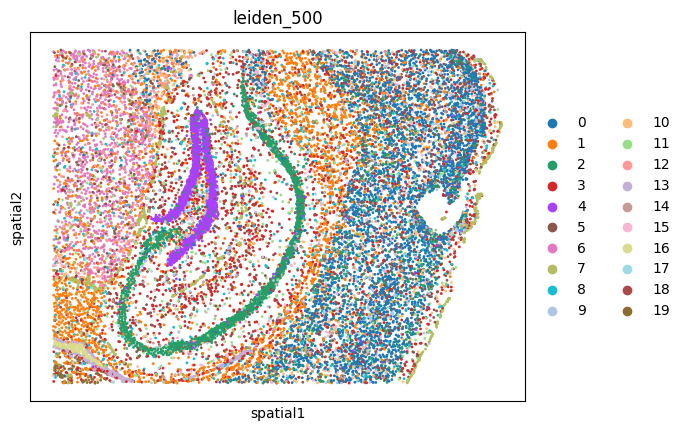

In [41]:
sc.pl.spatial(sdata['table'],color=['leiden_500'],spot_size=20)

In [42]:
# Obtain cluster-specific differentially expressed genes
sc.tl.rank_genes_groups(sdata['table'], groupby="leiden_500", method="wilcoxon")

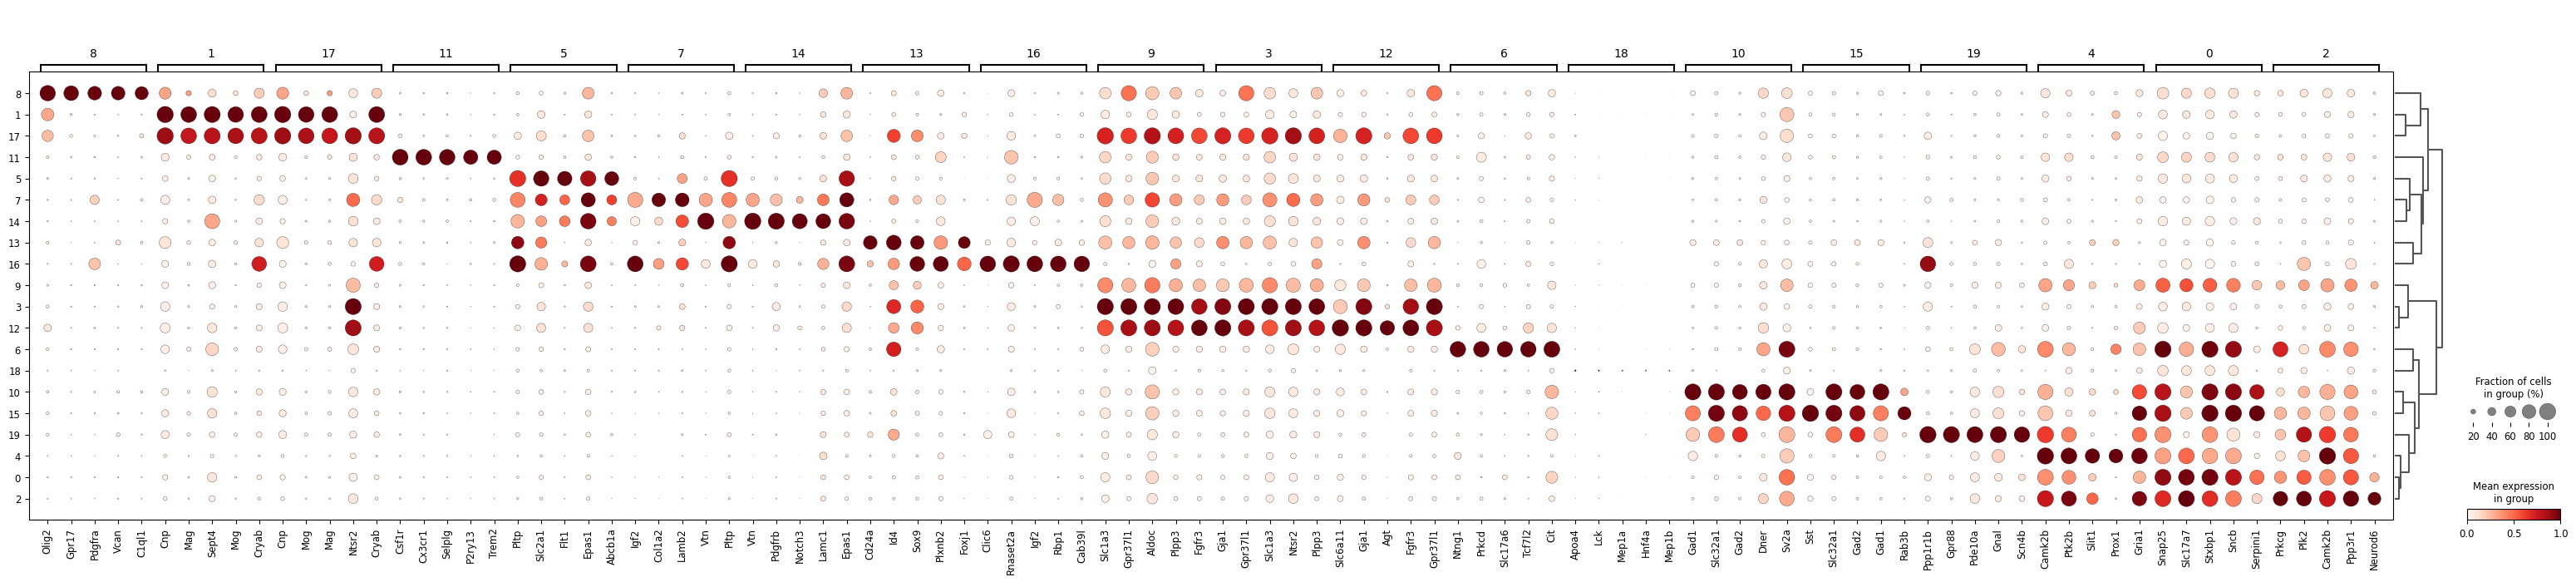

In [43]:
sc.pl.rank_genes_groups_dotplot(sdata['table'], groupby="leiden_500", standard_scale="var", n_genes=5)

In [46]:
annodict={0:'Excitatory neurons',1:'Oligo-1',2:'CA',3:'Astro-1',4:'DG',5:'Endothelial',6:'Thalamic neurons',
7:'Vascular cells',8:'OPC',9:'Astro-2',10:'Inhibitory neurons-1',11:'Microglia',12:'Astro-3',
13:'Ependymal',14:'Smooth muscle cells',15:'Inhibitory neurons-2',16:'Choroid plexus',17:'Oligo-2',18:'Excitatory neurons',19:'Inhibitory neurons-3'}

In [47]:
sdata['table'].obs['cell_type']=sdata['table'].obs['leiden_500'].astype(int).map(annodict)

In [50]:
trans=sdata['transcripts'].compute()

In [51]:
trans_sub=trans[trans['gene'].isin(sdata['table'].var.index)]

In [ ]:
sdata['transcripts']=sd.models.PointsModel.parse(trans_sub)

In [57]:
sdata.write('/media/sergio/Meninges/annotated_msbrain_5k_reduced.zarr',overwrite=True)

SpatialData object, with associated Zarr store: /media/sergio/Meninges/troutpy/rois/xenium_msbrain_5k/data_processed.zarr
├── Images
│     └── 'morphology_focus': DataTree[cyx] (5, 11300, 16004), (5, 5650, 8002), (5, 2825, 4001), (5, 1412, 2000), (5, 706, 1000)
├── Labels
│     ├── 'cell_labels': DataTree[yx] (11300, 16004), (5650, 8002), (2825, 4001), (1412, 2000), (706, 1000)
│     └── 'nucleus_labels': DataTree[yx] (11300, 16004), (5650, 8002), (2825, 4001), (1412, 2000), (706, 1000)
├── Points
│     ├── 'extracellular_transcripts': DataFrame with shape: (<Delayed>, 21) (3D points)
│     └── 'transcripts': DataFrame with shape: (<Delayed>, 21) (3D points)
├── Shapes
│     ├── 'cell_boundaries': GeoDataFrame shape: (19958, 1) (2D shapes)
│     ├── 'cell_circles': GeoDataFrame shape: (19836, 2) (2D shapes)
│     ├── 'grid_squares': GeoDataFrame shape: (81940, 1) (2D shapes)
│     └── 'nucleus_boundaries': GeoDataFrame shape: (19865, 1) (2D shapes)
└── Tables
      ├── 'segmentation_fr

In [58]:
del sdata['extracellular_transcripts']
del sdata['segmentation_free_table']
del sdata['xrna_metadata']

In [68]:
bool_columns = [
    'is_gene', 'overlaps_nucleus', 'control_probe',
    'overlaps_cell', 'match_cell_signature', 'extracellular'
]

for col in bool_columns:
    if col in trans_sub.columns:
        trans_sub[col] = trans_sub[col].astype(str)


In [69]:
sdata['transcripts']=sd.models.PointsModel.parse(trans_sub)

In [71]:
sdata.write('/media/sergio/Meninges/annotated_msbrain_5k_reduced.zarr',overwrite=True)

INFO     The SpatialData object is not self-contained (i.e. it contains some elements that are Dask-backed from    
         locations outside /media/sergio/Meninges/annotated_msbrain_5k_reduced.zarr). Please see the documentation 
         of `is_self_contained()` to understand the implications of working with SpatialData objects that are not  
         self-contained.                                                                                           
INFO     The Zarr backing store has been changed from                                                              
         /media/sergio/Meninges/troutpy/rois/xenium_msbrain_5k/data_processed.zarr the new file path:              
         /media/sergio/Meninges/annotated_msbrain_5k_reduced.zarr                                                  
